# Structural Steel MFA 1931-2100

## Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from odym import dynamic_stock_model as dsm
from scipy import stats
from scipy.interpolate import interp1d
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from scipy.optimize import curve_fit
import weibull
from scipy.stats import linregress 
import matplotlib.lines as mlines
import matplotlib.ticker as mtick
from matplotlib.ticker import PercentFormatter
import plotly.graph_objects as go

c:\Users\aorga\Lib\site-packages\weibull\__init__.py:9: UserWarning: The "weibull" module is being superceded by the "reliability" module and will no longer be maintained. Please refactor your code for this alternative model and thank you for using weibull!
  warnings.warn('The "weibull" module is being superceded by the "reliability" module and will no longer be maintained. '


## Read in Data

In [2]:
df_steel = pd.read_csv(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_production.csv', index_col=0)
df_population = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_population.csv", index_col=0)
df_gdp = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_GDP.csv", index_col=0)
# df_floorspace = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\2016_01_10 Levesque FS per capita.xlsx', skiprows=7, index_col=0)
df_gdp_SSP2 = pd.read_excel(r'C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\Jay MFA Code\Bldg_Stock-master\InputData\Pop_Data.xlsx', sheet_name='GDP_pc', index_col=0)

In [3]:
df_recycling = pd.read_csv(r"C:\Users\aorga\OneDrive\Documents\01_CU\00_Research\02_US Structural Steel MFA\input_data_recycling.csv", index_col=0)

In [4]:
df_recycling

,scrap,Exports,Imports
1998,73000,5950,3370
1999,71000,5560,4020
2000,74000,5810,3630
2001,71000,7530,2810
2002,69000,9000,3320
2003,65000,10900,3690
2004,66600,11800,4790
2005,65600,13000,4000
2006,65300,14100,5000
2007,65000,16700,3780


In [5]:
df_population

,pop_ssp1,pop_ssp2,pop_ssp3,pop_ssp4,pop_ssp5,Source
1931,124039648.0,124039648.0,124039648.0,124039648.0,124039648.0,U.S. Censusu Bureau
1932,124840471.0,124840471.0,124840471.0,124840471.0,124840471.0,U.S. Censusu Bureau
1933,125578763.0,125578763.0,125578763.0,125578763.0,125578763.0,U.S. Censusu Bureau
1934,126373773.0,126373773.0,126373773.0,126373773.0,126373773.0,U.S. Censusu Bureau
1935,127250232.0,127250232.0,127250232.0,127250232.0,127250232.0,U.S. Censusu Bureau
...,...,...,...,...,...,...
2080,392501973.0,404260551.0,420497001.0,348010415.0,448127860.0,IIASA
2085,392186330.0,406044541.0,429693201.0,341897990.0,450578954.0,IIASA
2090,390155587.0,406645230.0,439152913.0,334254837.0,450632128.0,IIASA
2095,386290251.0,406411009.0,449283549.0,325383215.0,448101727.0,IIASA


## Clean / Prep Data

In [6]:
# ## Clean up floorspace DF ##
# df_floorspace = df_floorspace.iloc[0]
# df_floorspace = pd.DataFrame([df_floorspace])
# df_floorspace = df_floorspace.T

In [7]:
df_gdp

,gdp_ssp1,gdp_ssp2,gdp_ssp3,gdp_ssp4,gdp_ssp5,Source
1931,9931.00,9931.00,9931.00,9931.00,9931.00,Maddison Project
1932,8381.00,8381.00,8381.00,8381.00,8381.00,Maddison Project
1933,8048.00,8048.00,8048.00,8048.00,8048.00,Maddison Project
1934,8667.00,8667.00,8667.00,8667.00,8667.00,Maddison Project
1935,9681.00,9681.00,9681.00,9681.00,9681.00,Maddison Project
...,...,...,...,...,...,...
2080,119442.20,106697.52,83008.20,114520.71,157204.91,IIASA
2085,124303.92,110592.55,83593.36,118310.73,169937.36,IIASA
2090,129375.05,114706.62,84227.38,122246.85,183727.02,IIASA
2095,134619.76,118978.81,84841.97,126292.32,198572.54,IIASA


In [8]:
## Get gpd DF
df_gdp.index = df_gdp.index.astype(int)  # ensure index is numeric
df_gdp = df_gdp.sort_index()
df_gdp = df_gdp.reindex(
    range(df_gdp.index.min(), df_gdp.index.max() + 1)
)

cols = ['gdp_ssp1','gdp_ssp2','gdp_ssp3','gdp_ssp4','gdp_ssp5']

df_gdp[cols] = (
    df_gdp[cols]
      .apply(pd.to_numeric, errors='coerce')
      .interpolate(method='cubic')
)

df_gdp= df_gdp.loc[df_gdp.index >= 1931]

In [9]:
df_gdp

,gdp_ssp1,gdp_ssp2,gdp_ssp3,gdp_ssp4,gdp_ssp5,Source
1931,9931.000000,9931.000000,9931.000000,9931.000000,9931.000000,Maddison Project
1932,8381.000000,8381.000000,8381.000000,8381.000000,8381.000000,Maddison Project
1933,8048.000000,8048.000000,8048.000000,8048.000000,8048.000000,Maddison Project
1934,8667.000000,8667.000000,8667.000000,8667.000000,8667.000000,Maddison Project
1935,9681.000000,9681.000000,9681.000000,9681.000000,9681.000000,Maddison Project
...,...,...,...,...,...,...
2096,135685.626691,119845.660276,84960.532000,127108.928937,201666.721758,NaN
2097,136756.375509,120715.274883,85077.573401,127926.765039,204802.294777,NaN
2098,137831.680982,121587.065352,85193.064801,128745.280673,207979.129917,NaN
2099,138911.217636,122460.443214,85306.976801,129563.928205,211197.098038,NaN


In [10]:
## Get pop DF
df_population.index = df_population.index.astype(int)  # ensure index is numeric
df_population = df_population.sort_index()
df_population = df_population.reindex(
    range(1931, 2100+1)
)

cols = ['pop_ssp1','pop_ssp2','pop_ssp3','pop_ssp4','pop_ssp5']

df_population[cols] = (
    df_population[cols]
      .interpolate(method='cubic')
)


In [11]:
df_population

,pop_ssp1,pop_ssp2,pop_ssp3,pop_ssp4,pop_ssp5,Source
1931,1.240396e+08,1.240396e+08,1.240396e+08,1.240396e+08,1.240396e+08,U.S. Censusu Bureau
1932,1.248405e+08,1.248405e+08,1.248405e+08,1.248405e+08,1.248405e+08,U.S. Censusu Bureau
1933,1.255788e+08,1.255788e+08,1.255788e+08,1.255788e+08,1.255788e+08,U.S. Censusu Bureau
1934,1.263738e+08,1.263738e+08,1.263738e+08,1.263738e+08,1.263738e+08,U.S. Censusu Bureau
1935,1.272502e+08,1.272502e+08,1.272502e+08,1.272502e+08,1.272502e+08,U.S. Censusu Bureau
...,...,...,...,...,...,...
2096,3.852488e+08,4.062801e+08,4.514007e+08,3.234784e+08,4.472286e+08,NaN
2097,3.841043e+08,4.061230e+08,4.535483e+08,3.215325e+08,4.462173e+08,NaN
2098,3.828507e+08,4.059405e+08,4.557263e+08,3.195466e+08,4.450611e+08,NaN
2099,3.814823e+08,4.057335e+08,4.579347e+08,3.175217e+08,4.437532e+08,NaN


In [ ]:
## Identify 1931 Base stock ## 
#base_stock = df_floorspace.loc[1931,'Total U.S. floor space (million sq ft)']*0.101818*0.25*68

NameError: name 'df_floorspace' is not defined

For now, base stock is calculated from Levesque et al (2016) estimate of floorespace in 1931, percentage of structural steel calculated given the AISC white paper data, Pomponi et al's finding that structural steel is about 68 kg / ft^2 MI, and a rough estimation of the amount of buldings in 1931 one that had steel structures (currently assumed to be 25%) **TO BE VERIFIED IN FUTURE MODEL** 

## Get elasticities of Populatiopn and steel and GDP/cap and steel

In [13]:
## Create Elasticities df
df_elasticities = pd.concat([df_population['pop_ssp2'],df_gdp['gdp_ssp2'],df_steel['total-production']],axis = 1)

In [ ]:
df_elasticities

,pop_ssp2,gdp_ssp2,total-production
1931,1.240396e+08,9931.000000,23536.93607
1932,1.248405e+08,8381.000000,12411.20919
1933,1.255788e+08,8048.000000,21075.74094
1934,1.263738e+08,8667.000000,23636.72651
1935,1.272502e+08,9681.000000,30928.68612
...,...,...,...
2096,4.062801e+08,119845.660276,NaN
2097,4.061230e+08,120715.274883,NaN
2098,4.059405e+08,121587.065352,NaN
2099,4.057335e+08,122460.443214,NaN


In [14]:
df_elasticities = df_elasticities.loc[1931:2023]

In [15]:
#df_elasticities['Total Steel (tons)'] = df_elasticities['Total Steel (Thousand Tons)']*1000


In [16]:
#df_elasticities['GDP/Capita'] = df_elasticities['SSP2']

In [17]:
#df_elasticities['Total Steel (tons)']

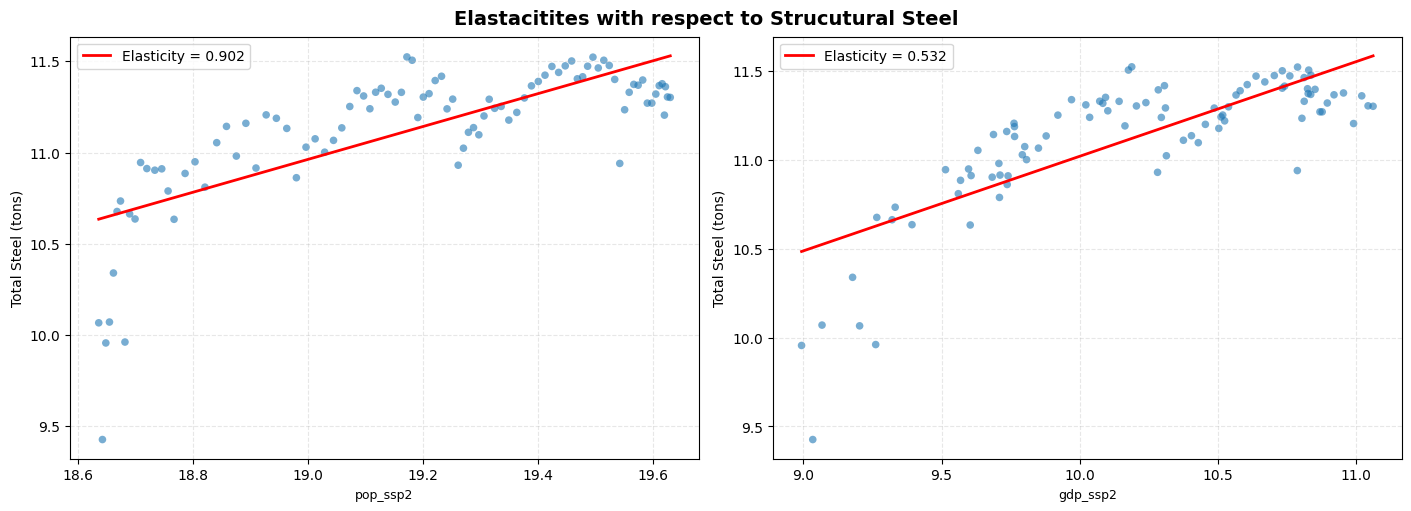

In [18]:
### Graph Relationship 

fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize=(14,5), constrained_layout = True)
axes = axes.flatten()

xcols = ['pop_ssp2', 'gdp_ssp2']

for xcol, ax in zip(xcols, axes):
    x = np.log(df_elasticities[xcol].loc[1931:2023])
    y = np.log(df_elasticities['total-production'].loc[1931:2023])
    ax.scatter(x,y, alpha = 0.6, s = 30, color = 'tab:blue', edgecolor = 'none')

    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() > 1:
        slope, intercept, r_value, p_value, std_err = linregress(x[mask], y[mask])

        # slope = elasticity
        X_sorted = np.sort(x[mask])
        ax.plot(X_sorted, intercept + slope*X_sorted, 
                color='red', lw=2, 
                label=f"Elasticity = {slope:.3f}")
    ax.set_xlabel(xcol,fontsize = 9)
    ax.set_ylabel('Total Steel (tons)')
    ax.grid(True, linestyle = '--', alpha = 0.3)
    ax.legend(loc = 'upper left')

for ax in axes[len(xcols):]:
    ax.set_visible(False)

fig.suptitle('Elastacitites with respect to Strucutural Steel', fontsize = 14, fontweight = 'bold')
plt.show()

## Forecasting Population and Economic Data

In [19]:
#### Get Variables and Constants for Forecast ####
# Percantage of structural steel 


### GDP linear regression
# X_gdp = np.array(df_gdp_SSP2.index).reshape(-1, 1)
# # y_gdp = df_gdp_SSP2["SSP2"].values
# gdp_model = LinearRegression()
# gdp_model.fit(X_gdp, y_gdp)

# # Get GDP elasticity approx 
# gdp_elast = gdp_model.coef_[0]


# ### Population Regression
# def logistic(t, K, r, t0):
#     return K / (1 + np.exp(-r * (t - t0)))

# ## Fit model
# t = df_population.index.values.astype(float)
# P = df_population["Population (Thousands)"].values

# p0 = [P.max() * 1.1, 0.03, 2000]

# params, covariance = curve_fit(logistic, t, P, p0=p0, maxfev=10000)
# K, r, t0 = params

# ## Population elasticity Approx
# P_hat = logistic(t, K, r, t0)
# pop_elast = r * (1 - P_hat / K) * t
# pop_elast_series = pd.Series(pop_elast, index=df_population.index, name="pop_elasticity")

In [436]:
## Define elasticities

pop_elast = 0.902
gdp_elast = 0.528
stuctural_constant = (8400/82500)*0.49

In [437]:
stuctural_constant 

0.04989090909090909

## Forecast Structural Steel Inflows 

In [438]:
### Forcast 
df_steel.index = df_steel.index.astype(int)
df_population.index = df_population.index.astype(int)
df_gdp.index = df_gdp.index.astype(int)

#build forecast years
forecast_years = np.arange(2024, 2101)

pop_fore = df_population.loc[forecast_years, "pop_ssp1"]
gdp_fore = df_gdp.loc[forecast_years, "gdp_ssp1"]


steel_fore_vals = stuctural_constant * ((gdp_fore ** gdp_elast) + (pop_fore ** pop_elast)) 


df_steel_forecast = pd.DataFrame({
    "structural-total": steel_fore_vals,
}, index=forecast_years)

In [439]:
df_steel

,total-production,structural-total
1931,23536.93607,2396.48
1932,12411.20919,1263.68
1933,21075.74094,2145.89
1934,23636.72651,2406.64
1935,30928.68612,3149.10
...,...,...
2019,87300.00000,8888.71
2020,73500.00000,7483.62
2021,85900.00000,8746.17
2022,81200.00000,8267.62


In [440]:
df_steel_forecast

,structural-total
2024,2.451004e+06
2025,2.487637e+06
2026,2.516863e+06
2027,2.531633e+06
2028,2.536864e+06
...,...
2096,2.769262e+06
2097,2.761841e+06
2098,2.753709e+06
2099,2.744830e+06


In [604]:
def forecast_structural_steel(
    df_population,
    df_gdp,
    structural_constant,
    gdp_elast,
    pop_elast,
    scenarios=range(1, 6),
    start_year=2024,
    end_year=2100,
    scale=1,
):
    df_population = df_population.copy()
    df_gdp = df_gdp.copy()
    df_population.index = df_population.index.astype(int)
    df_gdp.index = df_gdp.index.astype(int)

    forecast_years = np.arange(start_year, end_year + 1)

    data = {}
    for s in scenarios:
        pop_col = f"pop_ssp{s}"
        gdp_col = f"gdp_ssp{s}"

        pop_fore = df_population.loc[forecast_years, pop_col]
        gdp_fore = df_gdp.loc[forecast_years, gdp_col]

        steel_fore_vals = structural_constant * ((gdp_fore) + (pop_fore))
        
        data[f"structural_ssp{s}"] = steel_fore_vals / scale

    df_steel_forecast = pd.DataFrame(data, index=forecast_years)
    df_steel_forecast.index.name = "year"

    return df_steel_forecast

In [ ]:
df_steel_forecast = forecast_structural_steel(
    df_population=df_population,
    df_gdp=df_gdp,
    structural_constant=stuctural_constant,  # your spelling
    gdp_elast=gdp_elast,
    pop_elast=pop_elast,
    scenarios=range(1, 6),      # SSP1–SSP5
    start_year=2024,
    end_year=2100,
    scale=1e5
)


In [606]:
df_steel_forecast

,structural_ssp1,structural_ssp2,structural_ssp3,structural_ssp4,structural_ssp5
year,,,,,
2024,1679.062231,1679.062249,1679.063243,1679.062808,1679.059731
2025,1706.905790,1706.651670,1699.725932,1702.541505,1724.854382
2026,1729.152886,1728.699095,1716.291472,1720.980154,1761.764739
2027,1740.409216,1739.879709,1725.301166,1730.115467,1779.606578
2028,1744.400511,1743.879358,1729.332078,1733.037808,1784.882643
...,...,...,...,...,...
2096,1922.718441,2027.566238,2252.503030,1614.497224,2232.270197
2097,1917.013501,2026.786857,2263.217986,1604.793035,2227.240423
2098,1910.764700,2025.880883,2274.084754,1594.889155,2221.487856


In [607]:
## Create single dataset ##
historic_years = df_steel.index
historic = df_steel.iloc[:,1]

historic.index = historic.index.astype(int)
df_steel_forecast.index = df_steel_forecast.index.astype(int)

historic = pd.DataFrame(
    {col: historic for col in df_steel_forecast.columns}
)

MFA_Data_Total = pd.concat([historic, df_steel_forecast], axis=0)

In [608]:
MFA_Data_Total.loc[2020:2025]

,structural_ssp1,structural_ssp2,structural_ssp3,structural_ssp4,structural_ssp5
2020,7483.620000,7483.620000,7483.620000,7483.620000,7483.620000
2021,8746.170000,8746.170000,8746.170000,8746.170000,8746.170000
2022,8267.620000,8267.620000,8267.620000,8267.620000,8267.620000
2023,8247.260000,8247.260000,8247.260000,8247.260000,8247.260000
2024,1679.062231,1679.062249,1679.063243,1679.062808,1679.059731
2025,1706.905790,1706.651670,1699.725932,1702.541505,1724.854382


## Perform MFA

In [609]:
## Define survival Function
def generate_lt(type, par1, par2):
    ''' Normal: par1  = mean, par2 = std. dev
        Weibull: par1 = shape, par2 = scale'''
    if type=='Normal':
        # Normal
        lt = {'Type': type, 'Mean': np.array([par1] * len(years)), 'StdDev': par2}
    elif type=='Weibull':
        # Weibull 
            lt = {'Type': type, 'Shape': np.array([par1]), 'Scale': np.array([par2])}
    return lt   

# For testing shapes
x=np.arange(1,170)
def weib(x,n,a):
    return (a/n) * (x/n)**(a-1) * np.exp(-(x/n)**a)

In [610]:

lt_buildings = generate_lt('Weibull',par1=5,par2=85)

Text(0.5, 0, 'Age to Failuire')

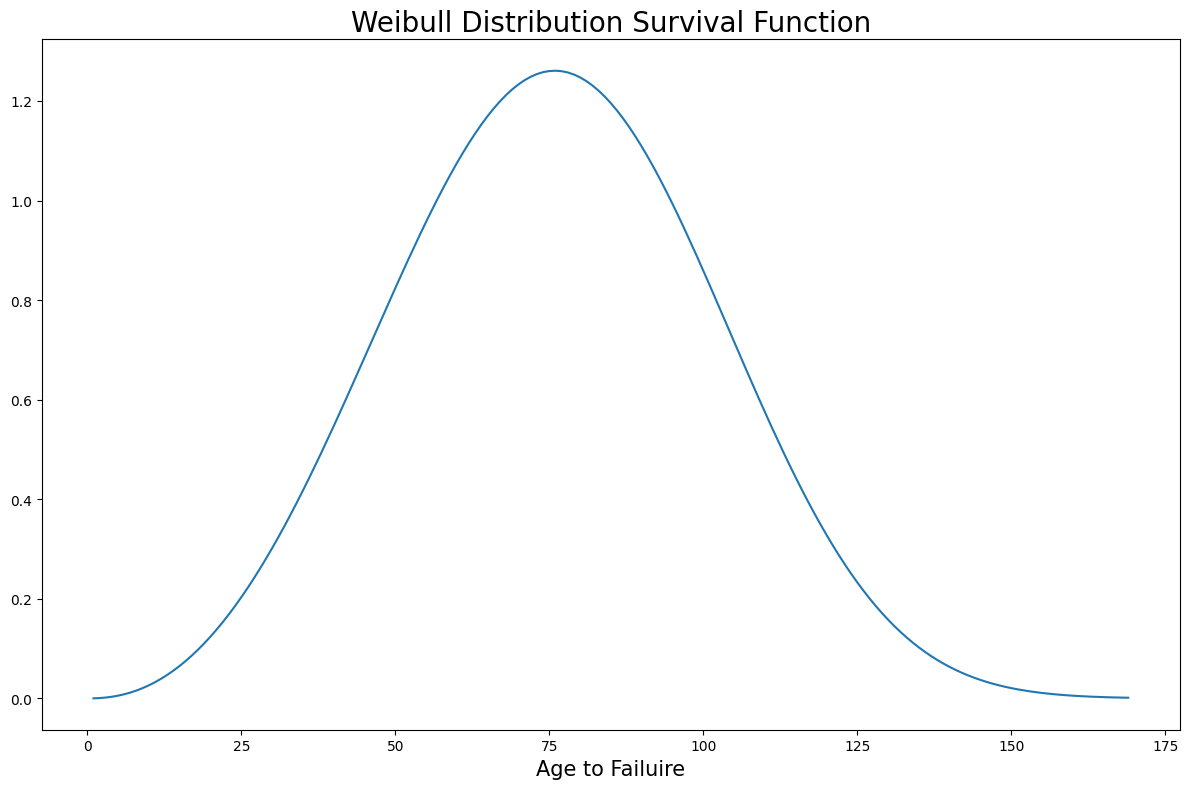

In [611]:
## See weibull shapes
lt_buildings = generate_lt('Weibull',par1=3.25,par2=85)

plt.plot(x, weib(x, lt_buildings['Scale'][0], lt_buildings['Shape'][0])*lt_buildings['Scale'][0])
plt.title('Weibull Distribution Survival Function', fontsize = 20)
plt.xlabel('Age to Failuire', fontsize = 15)

In [612]:
MFA_Data_Total

,structural_ssp1,structural_ssp2,structural_ssp3,structural_ssp4,structural_ssp5
1931,2396.480000,2396.480000,2396.480000,2396.480000,2396.480000
1932,1263.680000,1263.680000,1263.680000,1263.680000,1263.680000
1933,2145.890000,2145.890000,2145.890000,2145.890000,2145.890000
1934,2406.640000,2406.640000,2406.640000,2406.640000,2406.640000
1935,3149.100000,3149.100000,3149.100000,3149.100000,3149.100000
...,...,...,...,...,...
2096,1922.718441,2027.566238,2252.503030,1614.497224,2232.270197
2097,1917.013501,2026.786857,2263.217986,1604.793035,2227.240423
2098,1910.764700,2025.880883,2274.084754,1594.889155,2221.487856
2099,1903.942752,2024.852277,2285.103463,1584.790785,2214.978727


In [613]:
## Perform MFA ssp1
years = MFA_Data_Total.index

steel_DSM_ssp1 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp1']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

In [614]:
## Define aspects of MFA
stock_by_cohort =  steel_DSM_ssp1.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp1.dimension_check()
S_steel = steel_DSM_ssp1.compute_stock_total() 
O_C = steel_DSM_ssp1.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp1.compute_stock_change()
O_steel = steel_DSM_ssp1.compute_outflow_total()

In [615]:
## Perform MFA ssp2

steel_DSM_ssp2 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp2']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp2.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp2.dimension_check()
S_steel = steel_DSM_ssp2.compute_stock_total() 
O_C = steel_DSM_ssp2.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp2.compute_stock_change()
O_steel = steel_DSM_ssp2.compute_outflow_total()

In [616]:
## Perform MFA ssp3

steel_DSM_ssp3 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp3']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp3.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp3.dimension_check()
S_steel = steel_DSM_ssp3.compute_stock_total() 
O_C = steel_DSM_ssp3.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp3.compute_stock_change()
O_steel = steel_DSM_ssp3.compute_outflow_total()

In [617]:
## Perform MFA ssp4

steel_DSM_ssp4 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp4']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp4.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp4.dimension_check()
S_steel = steel_DSM_ssp4.compute_stock_total() 
O_C = steel_DSM_ssp4.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp4.compute_stock_change()
O_steel = steel_DSM_ssp4.compute_outflow_total()

In [618]:
## Perform MFA ssp5

steel_DSM_ssp5 = dsm.DynamicStockModel(t = np.array(years), i = np.array(MFA_Data_Total['structural_ssp5']), 
                                  lt = {'Type': 'Weibull', 'Shape': np.array([2.25]), 
                                        'Scale': np.array([85]) })

stock_by_cohort =  steel_DSM_ssp5.compute_s_c_inflow_driven()
CheckStr = steel_DSM_ssp5.dimension_check()
S_steel = steel_DSM_ssp5.compute_stock_total() 
O_C = steel_DSM_ssp5.compute_o_c_from_s_c()
DS_steel = steel_DSM_ssp5.compute_stock_change()
O_steel = steel_DSM_ssp5.compute_outflow_total()

In [619]:
# plt.imshow(steel_DSM.s_c)
# # ax[0,0].xlabel('age-cohort')
# plt.ylabel('year')
# plt.title('Stock by age-cohort in 2100')



Text(0.5, 1.0, 'Outflow by age-cohort')

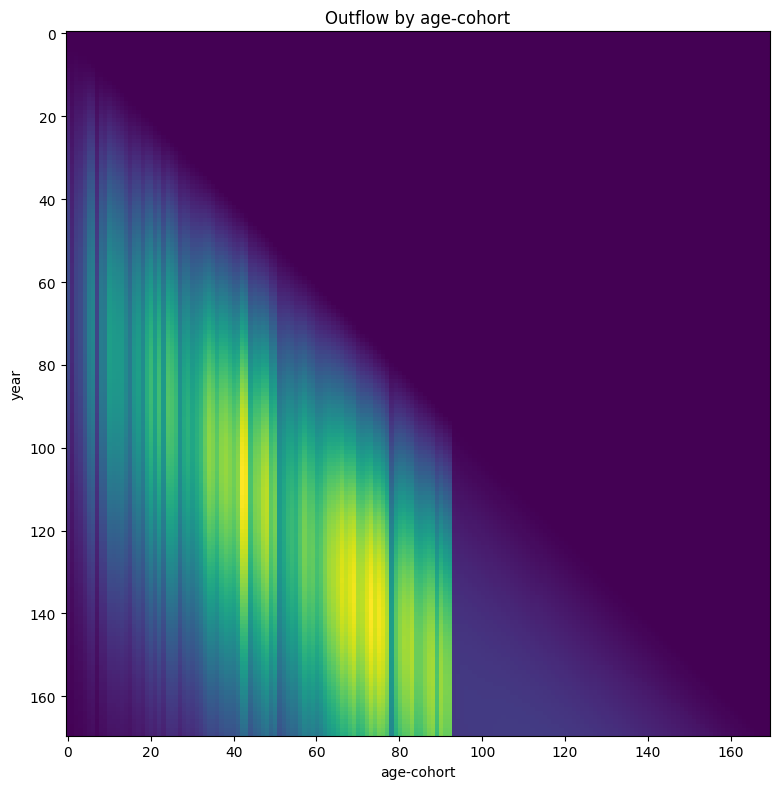

In [620]:
plt.imshow(steel_DSM_ssp2.o_c,interpolation='nearest')
plt.xlabel('age-cohort')
plt.ylabel('year')
plt.title('Outflow by age-cohort')

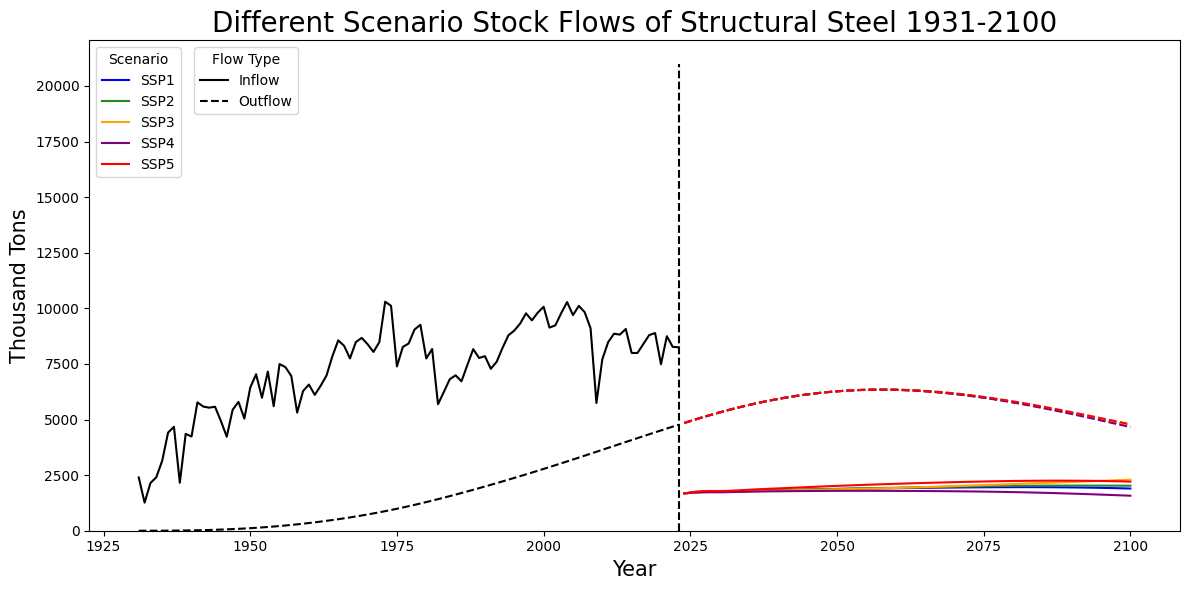

In [621]:
fig, ax = plt.subplots(figsize = (12,6))


ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.i[:93], color = 'black')
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.i[93:], color = 'blue')
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.i[93:], color = 'forestgreen')
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.i[93:], color = 'orange')
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.i[93:], color = 'purple')
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.i[93:], color = 'red')
ax.plot(steel_DSM_ssp1.t[:93], steel_DSM_ssp1.o[:93], color = 'black', ls = "--")
ax.plot(steel_DSM_ssp1.t[93:], steel_DSM_ssp1.o[93:], color = 'blue', ls = "--")
ax.plot(steel_DSM_ssp2.t[93:], steel_DSM_ssp2.o[93:], color = 'forestgreen', ls = "--")
ax.plot(steel_DSM_ssp3.t[93:], steel_DSM_ssp3.o[93:], color = 'orange', ls = "--")
ax.plot(steel_DSM_ssp4.t[93:], steel_DSM_ssp4.o[93:], color = 'purple', ls = "--")
ax.plot(steel_DSM_ssp5.t[93:], steel_DSM_ssp5.o[93:], color = 'red', ls = "--")
ax.plot([2023,2023],[0,21000], color = 'k', linestyle = '--')
plt.xlabel('Year', fontsize = 15)
plt.ylabel('Thousand Tons',fontsize = 15)
plt.title('Different Scenario Stock Flows of Structural Steel 1931-2100', fontsize = 20)
scenario_handles = [
    mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
]

leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
ax.add_artist(leg1)

inflow_line = mlines.Line2D([], [], color='black', linestyle='-', label='Inflow')
outflow_line = mlines.Line2D([], [], color='black', linestyle='--', label='Outflow')

flow_handles = [
    mlines.Line2D([], [], color='black', linestyle='-',  label='Inflow'),
    mlines.Line2D([], [], color='black', linestyle='--', label='Outflow'),
]

ax.set_ylim(0,)
ax.legend(handles=flow_handles, title='Flow Type', loc='upper left', bbox_to_anchor = (0.09,1))
plt.show()

In [622]:
df_steel

,total-production,structural-total
1931,23536.93607,2396.48
1932,12411.20919,1263.68
1933,21075.74094,2145.89
1934,23636.72651,2406.64
1935,30928.68612,3149.10
...,...,...
2019,87300.00000,8888.71
2020,73500.00000,7483.62
2021,85900.00000,8746.17
2022,81200.00000,8267.62


NameError: name 'all_flows' is not defined

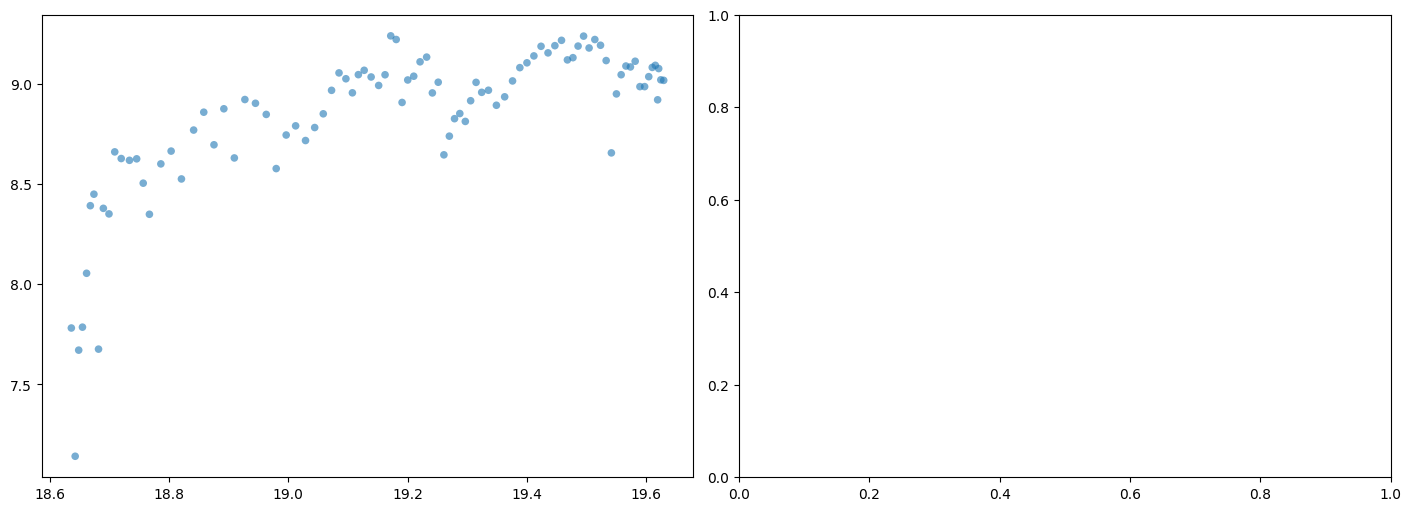

In [623]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize=(14,5), constrained_layout = True)

xcols = ['pop_ssp2', 'gdp_ssp2']

for xcol, ax in zip(xcols, axes):
    x = np.log(df_elasticities[xcol].loc[1931:2023])
    y = np.log(df_steel['structural-total'].loc[1931:2023])
    ax.scatter(x,y, alpha = 0.6, s = 30, color = 'tab:blue', edgecolor = 'none')
    x1 = np.log(all_flows[xcols].loc[2024:2100])
    ax.plot(x1, steel_DSM_ssp1.i[93:], color = 'blue')
    ax.plot(x1, steel_DSM_ssp2.i[93:],color = 'forestgreen')
    ax.plot(x1, steel_DSM_ssp3.i[93:],color = 'orange')
    ax.plot(x1, steel_DSM_ssp4.i[93:],color = 'purple')
    ax.plot(x1, steel_DSM_ssp5.i[93:],color = 'red')
    ax.set_xlabel(xcol,fontsize = 9)
    ax.set_ylabel('Structural Steel (kt)')
    ax.grid(True, linestyle = '--', alpha = 0.3)


    
scenario_handles = [
    mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
]

leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
ax.add_artist(leg1)

plt.show()

In [ ]:
## Create Dataframe of Flows ssp1
total_inflows_ssp1 = steel_DSM_ssp1.i
total_outflows_ssp1 = steel_DSM_ssp1.o
years = steel_DSM_ssp1.t

total_flows = pd.DataFrame({"inflow_ssp1":total_inflows_ssp1, 'outflow_ssp1':total_outflows_ssp1}, index=years)



In [ ]:
start_year = 1931
n_years = len(steel_DSM_ssp1.t)
years = np.arange(start_year, start_year + n_years)

# Build all SSP flow dataframes
flow_dfs = {}

for s in range(1, 6):   # SSP1–SSP5
    model = globals()[f"steel_DSM_ssp{s}"]   # get steel_DSM_ssp1, etc.

    df = pd.DataFrame({
        f"inflow_ssp{s}":  model.i,
        f"outflow_ssp{s}": model.o,
    }, index=years)

    df.index.name = "Year"

    flow_dfs[f"ssp{s}"] = df

all_flows = pd.concat(flow_dfs.values(), axis=1)

In [ ]:
all_flows.loc[2024]

inflow_ssp1     8503.632389
outflow_ssp1    4848.730711
inflow_ssp2     8503.891400
outflow_ssp2    4848.730711
inflow_ssp3     8517.690820
outflow_ssp3    4848.730711
inflow_ssp4     8511.648500
outflow_ssp4    4848.730711
inflow_ssp5     8468.818400
outflow_ssp5    4848.730711
Name: 2024, dtype: float64

In [ ]:
## ECCs
production_emissions = .898+.109
reuse_emissions = .109

Deconstruction / demolition emissions excluded, assumed to be the same for this. However, future versions of this model should note that deconstruction seemingly tends to have lower emissions associated with it

In [ ]:
total_flows['flows delta'] = total_flows['Total Inflow'] - total_flows['Total Outflow']
total_flows['demand percentage'] = total_flows['Total Outflow'] / total_flows['Total Inflow']

KeyError: 'Total Inflow'

In [ ]:
all_flows['demand percentage_ssp1'] = all_flows['outflow_ssp1'] / all_flows['inflow_ssp1']
all_flows['demand percentage_ssp2'] = all_flows['outflow_ssp2'] / all_flows['inflow_ssp2']
all_flows['demand percentage_ssp3'] = all_flows['outflow_ssp3'] / all_flows['inflow_ssp3']
all_flows['demand percentage_ssp4'] = all_flows['outflow_ssp4'] / all_flows['inflow_ssp4']
all_flows['demand percentage_ssp5'] = all_flows['outflow_ssp5'] / all_flows['inflow_ssp5']


In [ ]:
all_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,demand percentage_ssp1,demand percentage_ssp2,demand percentage_ssp3,demand percentage_ssp4,demand percentage_ssp5
Year,,,,,,,,,,,,,,,
1931,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1932,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,0.000086,0.000086,0.000086,0.000086,0.000086
1933,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,0.000218,0.000218,0.000218,0.000218,0.000218
1934,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,0.000452,0.000452,0.000452,0.000452,0.000452
1935,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,0.000655,0.000655,0.000655,0.000655,0.000655
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,14201.622937,9493.936118,13953.868896,9354.909692,12795.676320,9091.417243,11719.438547,9241.104993,20028.385990,10159.761821,0.668511,0.670417,0.710507,0.788528,0.507268
2097,14222.465173,9552.917646,14002.352993,9409.406196,12859.917825,9135.275727,11695.367333,9286.616504,20151.020878,10252.338274,0.671678,0.671988,0.710368,0.794042,0.508775
2098,14239.354343,9612.052171,14049.959193,9464.062907,12924.861871,9179.138952,11669.422198,9331.812848,20267.974601,10346.132697,0.675034,0.673601,0.710192,0.799681,0.510467


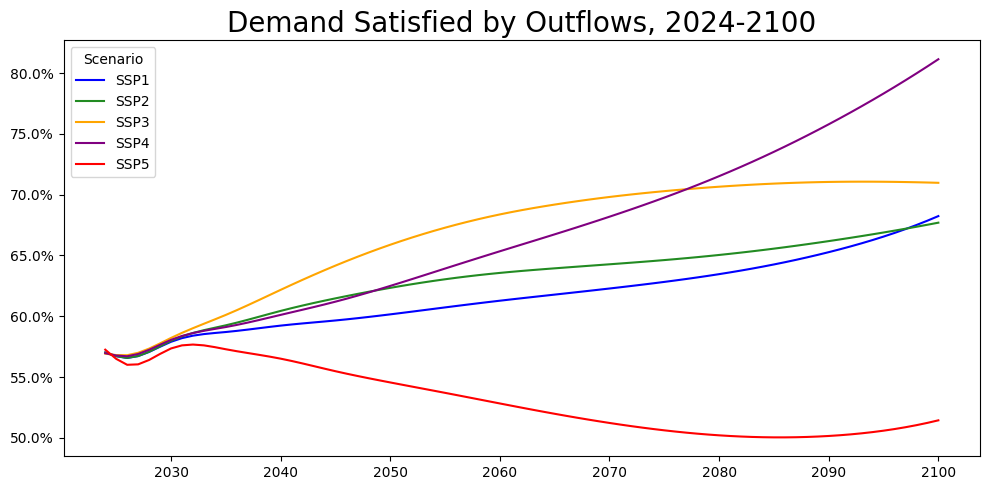

In [ ]:
fig,ax = plt.subplots(figsize = (10,5))

years = all_flows.loc[2024:2100].index
ax.plot(years, all_flows['demand percentage_ssp1'].loc[2024:2100], color = 'blue')
ax.plot(years, all_flows['demand percentage_ssp2'].loc[2024:2100], color = 'forestgreen')
ax.plot(years, all_flows['demand percentage_ssp3'].loc[2024:2100], color = 'orange')
ax.plot(years, all_flows['demand percentage_ssp4'].loc[2024:2100], color = 'purple')
ax.plot(years, all_flows['demand percentage_ssp5'].loc[2024:2100], color = 'red')


plt.title('Demand Satisfied by Outflows, 2024-2100', fontsize = 20)
scenario_handles = [
    mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
]

ax.yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')

KeyError: "None of [Index(['pop_ssp2', 'gdp_ssp2'], dtype='object')] are in the [columns]"

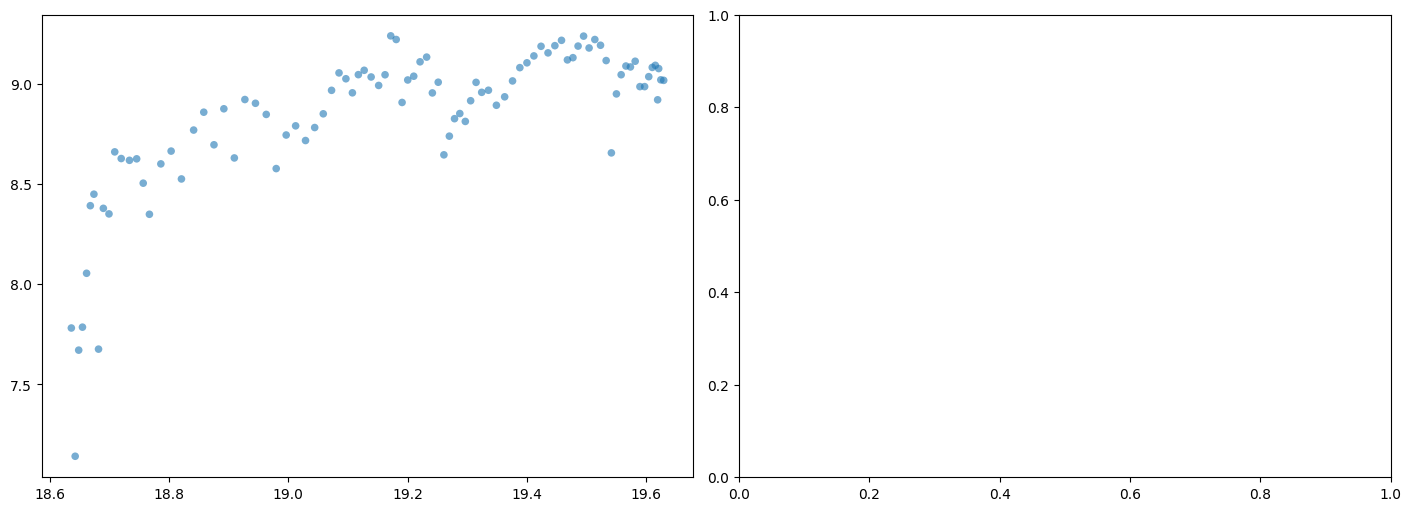

In [ ]:
fig, axes = plt.subplots(nrows = 1, ncols = 2, figsize=(14,5), constrained_layout = True)

xcols = ['pop_ssp2', 'gdp_ssp2']

for xcol, ax in zip(xcols, axes):
    x = np.log(df_elasticities[xcol].loc[1931:2023])
    y = np.log(df_steel['structural-total'].loc[1931:2023])
    ax.scatter(x,y, alpha = 0.6, s = 30, color = 'tab:blue', edgecolor = 'none')
    x1 = np.log(all_flows[xcols].loc[2024:2100])
    ax.plot(x1, steel_DSM_ssp1.i[93:], color = 'blue')
    ax.plot(x1, steel_DSM_ssp2.i[93:],color = 'forestgreen')
    ax.plot(x1, steel_DSM_ssp3.i[93:],color = 'orange')
    ax.plot(x1, steel_DSM_ssp4.i[93:],color = 'purple')
    ax.plot(x1, steel_DSM_ssp5.i[93:],color = 'red')
    ax.set_xlabel(xcol,fontsize = 9)
    ax.set_ylabel('Structural Steel (kt)')
    ax.grid(True, linestyle = '--', alpha = 0.3)


    
scenario_handles = [
    mlines.Line2D([], [], color='blue',        linestyle='-', label='SSP1'),
    mlines.Line2D([], [], color='forestgreen', linestyle='-', label='SSP2'),
    mlines.Line2D([], [], color='orange',      linestyle='-', label='SSP3'),
    mlines.Line2D([], [], color='purple',      linestyle='-', label='SSP4'),
    mlines.Line2D([], [], color='red',         linestyle='-', label='SSP5'),
]

leg1 = ax.legend(handles=scenario_handles, title='Scenario', loc='upper left')
ax.add_artist(leg1)

plt.show()

In [ ]:
## Add reuse emissions column
def get_emissions (df, outflows,emissions,output_name):
    df[output_name] = df[outflows].sum(axis=1)*emissions
    return df

In [ ]:
total_flows = get_emissions(all_flows, ['outflow_ssp1'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp1')

total_flows = get_emissions(all_flows, ['outflow_ssp2'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp2')

total_flows = get_emissions(all_flows, ['outflow_ssp3'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp3')

total_flows = get_emissions(all_flows, ['outflow_ssp4'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp4')

total_flows = get_emissions(all_flows, ['outflow_ssp5'], 
                            emissions = reuse_emissions, 
                            output_name = '100% Reuse Emissions_ssp5')

In [ ]:
total_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,demand percentage_ssp1,demand percentage_ssp2,demand percentage_ssp3,demand percentage_ssp4,demand percentage_ssp5,100% Reuse Emissions_ssp1,100% Reuse Emissions_ssp2,100% Reuse Emissions_ssp3,100% Reuse Emissions_ssp4,100% Reuse Emissions_ssp5
Year,,,,,,,,,,,,,,,,,,,,
1931,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1932,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,0.000086,0.000086,0.000086,0.000086,0.000086,0.011907,0.011907,0.011907,0.011907,0.011907
1933,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,0.000218,0.000218,0.000218,0.000218,0.000218,0.051006,0.051006,0.051006,0.051006,0.051006
1934,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,0.000452,0.000452,0.000452,0.000452,0.000452,0.118611,0.118611,0.118611,0.118611,0.118611
1935,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,0.000655,0.000655,0.000655,0.000655,0.000655,0.224784,0.224784,0.224784,0.224784,0.224784
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,14201.622937,9493.936118,13953.868896,9354.909692,12795.676320,9091.417243,11719.438547,9241.104993,20028.385990,10159.761821,0.668511,0.670417,0.710507,0.788528,0.507268,1034.839037,1019.685156,990.964479,1007.280444,1107.414038
2097,14222.465173,9552.917646,14002.352993,9409.406196,12859.917825,9135.275727,11695.367333,9286.616504,20151.020878,10252.338274,0.671678,0.671988,0.710368,0.794042,0.508775,1041.268023,1025.625275,995.745054,1012.241199,1117.504872
2098,14239.354343,9612.052171,14049.959193,9464.062907,12924.861871,9179.138952,11669.422198,9331.812848,20267.974601,10346.132697,0.675034,0.673601,0.710192,0.799681,0.510467,1047.713687,1031.582857,1000.526146,1017.167600,1127.728464


In [ ]:
total_flows = get_emissions(all_flows, ['outflow_ssp1'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp1')

total_flows = get_emissions(all_flows, ['outflow_ssp2'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp2')

total_flows = get_emissions(all_flows, ['outflow_ssp3'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp3')

total_flows = get_emissions(all_flows, ['outflow_ssp4'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp4')

total_flows = get_emissions(all_flows, ['outflow_ssp5'], 
                            emissions = production_emissions, 
                            output_name = '100% Recycling Emissions_ssp5')

In [ ]:
total_flows

,inflow_ssp1,outflow_ssp1,inflow_ssp2,outflow_ssp2,inflow_ssp3,outflow_ssp3,inflow_ssp4,outflow_ssp4,inflow_ssp5,outflow_ssp5,...,100% Reuse Emissions_ssp1,100% Reuse Emissions_ssp2,100% Reuse Emissions_ssp3,100% Reuse Emissions_ssp4,100% Reuse Emissions_ssp5,100% Recycling Emissions_ssp1,100% Recycling Emissions_ssp2,100% Recycling Emissions_ssp3,100% Recycling Emissions_ssp4,100% Recycling Emissions_ssp5
Year,,,,,,,,,,,,,,,,,,,,,
1931,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,2396.480000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
1932,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,1263.680000,0.109237,...,0.011907,0.011907,0.011907,0.011907,0.011907,0.110002,0.110002,0.110002,0.110002,0.110002
1933,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,2145.890000,0.467943,...,0.051006,0.051006,0.051006,0.051006,0.051006,0.471219,0.471219,0.471219,0.471219,0.471219
1934,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,2406.640000,1.088172,...,0.118611,0.118611,0.118611,0.118611,0.118611,1.095790,1.095790,1.095790,1.095790,1.095790
1935,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,3149.100000,2.062242,...,0.224784,0.224784,0.224784,0.224784,0.224784,2.076677,2.076677,2.076677,2.076677,2.076677
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2096,14201.622937,9493.936118,13953.868896,9354.909692,12795.676320,9091.417243,11719.438547,9241.104993,20028.385990,10159.761821,...,1034.839037,1019.685156,990.964479,1007.280444,1107.414038,9560.393671,9420.394059,9155.057164,9305.792728,10230.880154
2097,14222.465173,9552.917646,14002.352993,9409.406196,12859.917825,9135.275727,11695.367333,9286.616504,20151.020878,10252.338274,...,1041.268023,1025.625275,995.745054,1012.241199,1117.504872,9619.788069,9475.272040,9199.222657,9351.622819,10324.104642
2098,14239.354343,9612.052171,14049.959193,9464.062907,12924.861871,9179.138952,11669.422198,9331.812848,20267.974601,10346.132697,...,1047.713687,1031.582857,1000.526146,1017.167600,1127.728464,9679.336536,9530.311347,9243.392925,9397.135538,10418.555626


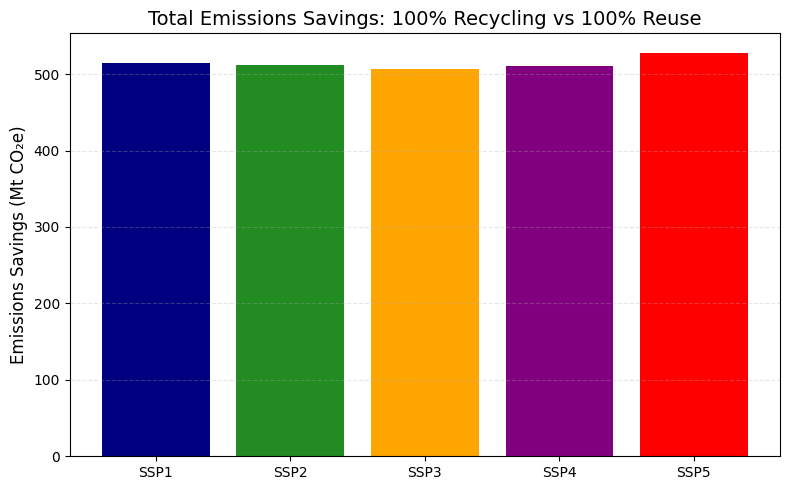

In [ ]:
ssp1_savings = (total_flows['100% Recycling Emissions_ssp1'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp1'].loc[2024:2100].sum())/1e3
ssp2_savings = (total_flows['100% Recycling Emissions_ssp2'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp2'].loc[2024:2100].sum())/1e3
ssp3_savings = (total_flows['100% Recycling Emissions_ssp3'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp3'].loc[2024:2100].sum())/1e3
ssp4_savings = (total_flows['100% Recycling Emissions_ssp4'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp4'].loc[2024:2100].sum())/1e3
ssp5_savings = (total_flows['100% Recycling Emissions_ssp5'].loc[2024:2100].sum() - total_flows['100% Reuse Emissions_ssp5'].loc[2024:2100].sum())/1e3

savings = [
    ssp1_savings,
    ssp2_savings,
    ssp3_savings,
    ssp4_savings,
    ssp5_savings
]

labels = ['SSP1', 'SSP2', 'SSP3', 'SSP4', 'SSP5']

plt.figure(figsize=(8,5))

plt.bar(labels, savings, color=[
    'navy', 'forestgreen', 'orange', 'purple', 'red'
])

plt.ylabel('Emissions Savings (Mt CO₂e)', fontsize=12)
plt.title('Total Emissions Savings: 100% Recycling vs 100% Reuse', fontsize=14)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.show()

KeyError: 'flows delta'

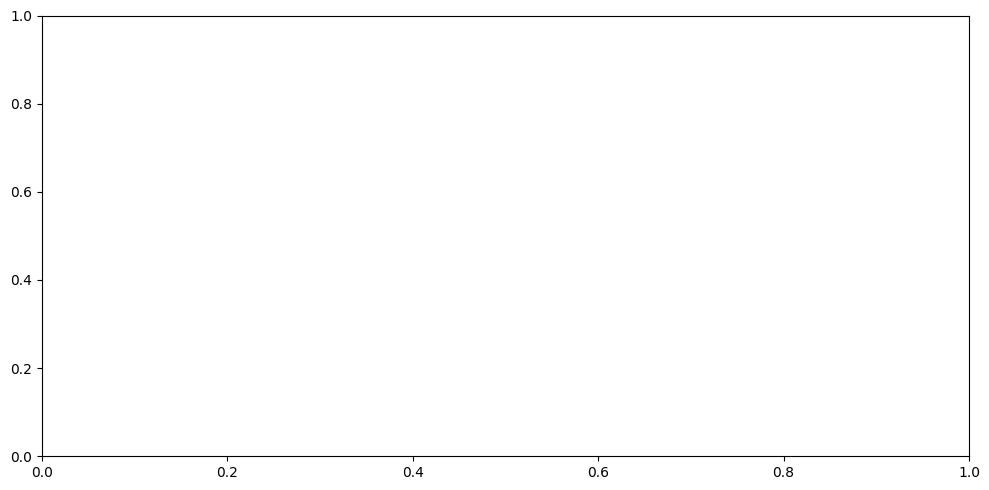

In [ ]:
fig,ax1 = plt.subplots(figsize = (10,5))

years = total_flows.loc[2024:2100].index
bar_vals = total_flows.loc[2024:2100, 'flows delta']

bars = ax1.bar(years, bar_vals, label="Delta", alpha=0.6)
ax1.set_xlabel("Year")
ax1.set_ylabel("Difference between Inflows and Outflows", color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()

line_vals = total_flows.loc[2024:2100, 'demand percentage']   # example second variable
ax2.plot(years, line_vals, label="Percentage ", linewidth=2, color = 'red')
ax2.set_ylabel("Percentage of Inflows Satisfied by Outflows", color='red')
ax2.tick_params(axis='y', labelcolor='red')
ax2.set_ylim(0,1)

plt.title('Relationship between Inflows and Outflows')
plt.show()

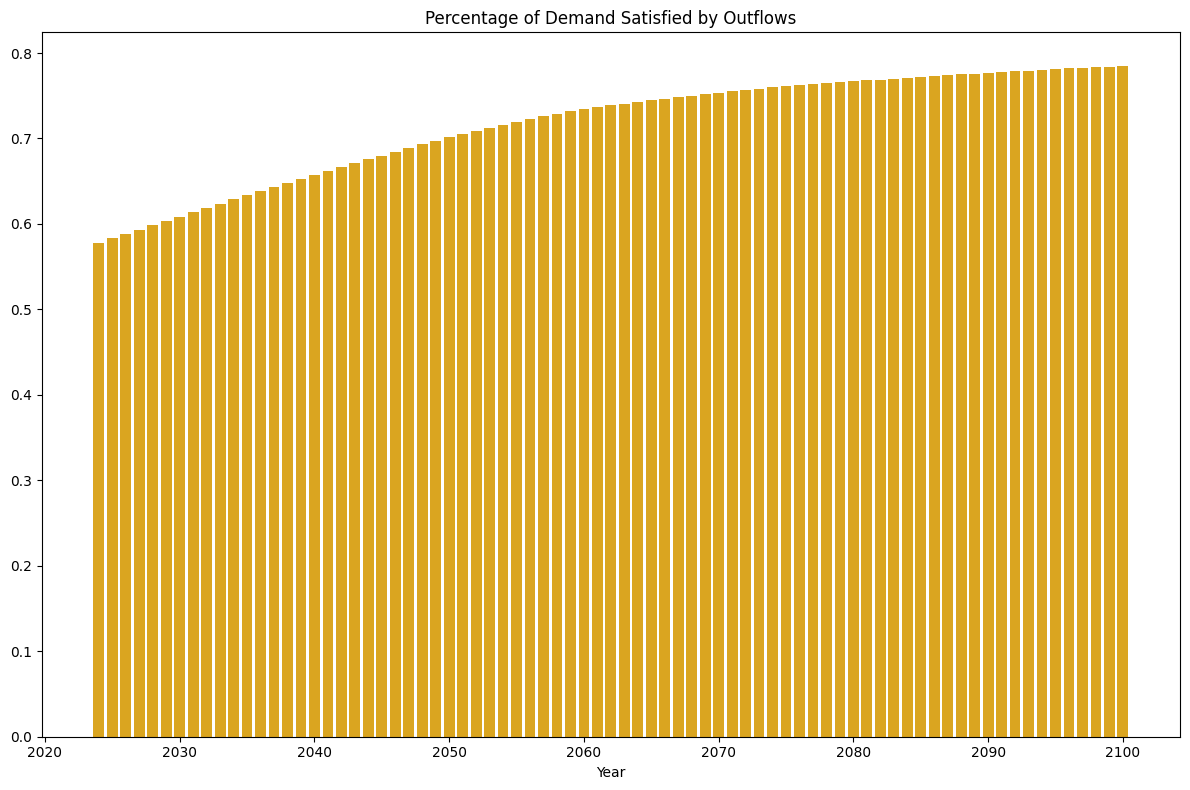

In [ ]:
plt1 = plt.bar(total_flows.loc[2024:2100].index, total_flows.loc[2024:2100, 'demand percentage'], color = 'goldenrod')
plt.xlabel('Year') 
plt.title('Percentage of Demand Satisfied by Outflows')
plt.show()

C:\Users\aorga\AppData\Local\Temp\ipykernel_39648\3869622933.py:6: UserWarning: Legend does not support handles for list instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  plt.legend([plt1,plt3], ['Reuse Emissions','Recycling Emissions'])


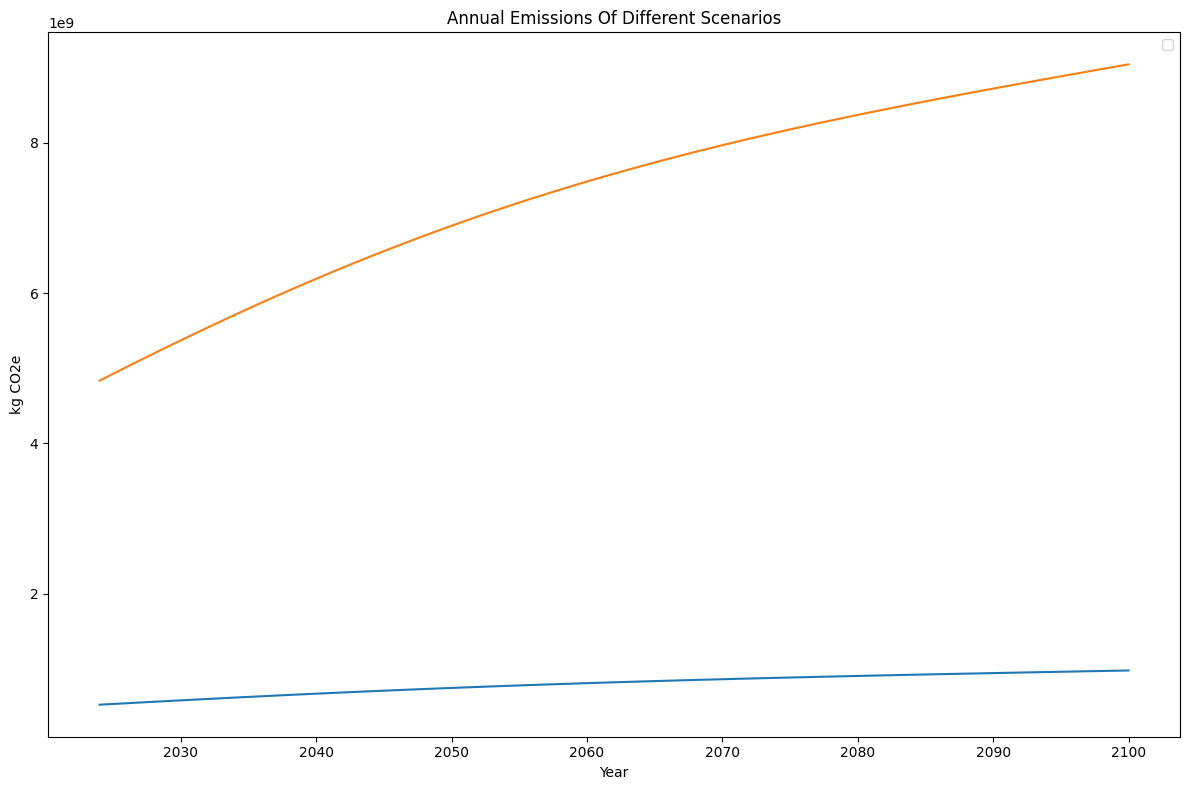

In [ ]:
plt1 = plt.plot(total_flows.loc[2024:2100].index, total_flows.loc[2024:2100, '100% Reuse Emissions'])
plt3 = plt.plot(total_flows.loc[2024:2100].index, total_flows.loc[2024:2100, '100% Recycling Emissions'])
plt.xlabel('Year')
plt.ylabel('kg CO2e')
plt.title('Annual Emissions Of Different Scenarios')
plt.legend([plt1,plt3], ['Reuse Emissions','Recycling Emissions'])
plt.show()

Text(0.001, 0.5, 'Megatons CO2e')

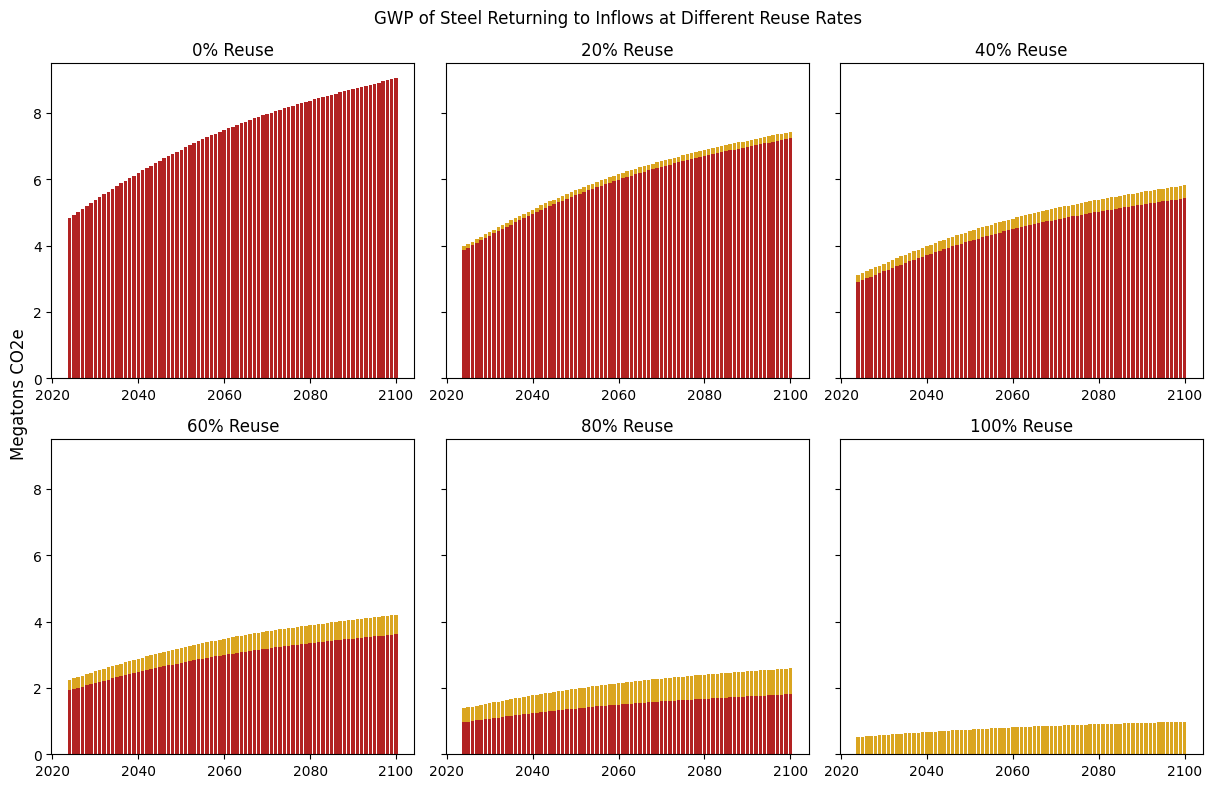

In [ ]:
fig, ax = plt.subplots(2,3, sharey=True)

ax[0,0].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']/1e3, color = 'firebrick')
ax[0,0].set_title('0% Reuse')

ax[0,1].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']*.8/1e3, color = 'firebrick')
ax[0,1].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']*.2/1e3,bottom=total_flows.loc[2024:2100, '100% Recycling Emissions']*.8/1e3, color = 'goldenrod')
ax[0,1].set_title('20% Reuse')

ax[0,2].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']*.6/1e3, color = 'firebrick')
ax[0,2].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']*.4/1e3,bottom=total_flows.loc[2024:2100, '100% Recycling Emissions']*.6/1e3, color = 'goldenrod')
ax[0,2].set_title('40% Reuse')

ax[1,0].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']*.4/1e3, color = 'firebrick')
ax[1,0].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']*.6/1e3,bottom=total_flows.loc[2024:2100, '100% Recycling Emissions']*.4/1e3, color = 'goldenrod')
ax[1,0].set_title('60% Reuse')

ax[1,1].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Recycling Emissions']*.2/1e3, color = 'firebrick')
ax[1,1].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']*.8/1e3,bottom=total_flows.loc[2024:2100, '100% Recycling Emissions']*.2/1e3, color = 'goldenrod')
ax[1,1].set_title('80% Reuse')

ax[1,2].bar(total_flows.loc[2024:2100].index,total_flows.loc[2024:2100, '100% Reuse Emissions']/1e3,color = 'goldenrod')
ax[1,2].set_title('100% Reuse')

fig.suptitle('GWP of Steel Returning to Inflows at Different Reuse Rates')
fig.text(0.001, 0.5, 'Megatons CO2e', ha='center', va='center', rotation = 'vertical', fontsize =12)

In [ ]:
total_flows['100% Recycling Emissions'].sum() - total_flows['100% Reuse Emissions'].sum()

np.float64(627917.7634190622)

Year
2024    336482000
2025    338016000
2026    339513000
2027    340970000
2028    342385000
          ...    
2096    366661000
2097    366393000
2098    366120000
2099    365841000
2100    365558000
Name: Population (Thousands), Length: 77, dtype: int64

In [ ]:
pop_proj = pop_fore.to_frame()
population = pd.concat([df_population,pop_proj],axis=0)

In [ ]:
population = population.iloc[31:201,:]

In [ ]:
population

,Population (Thousands),% Change Since Previous Year
Year,,
1931,124039648,0.78
1932,124840471,0.64
1933,125578763,0.59
1934,126373773,0.63
1935,127250232,0.69
...,...,...
2096,366661000,-0.07
2097,366393000,-0.07
2098,366120000,-0.07


In [ ]:
gdp_proj = pd.concat([df_gdp_SSP2,gdp_fore.to_frame()],axis=0)

In [ ]:
gdp_proj = gdp_proj.iloc[0:170]

In [ ]:
GFA_proj = 0.61 * (gdp_fore ** gdp_elast)* (pop_fore ** pop_elast_fore) 


In [ ]:
gfa_forecast = pd.DataFrame({
    "Total U.S. floor space (million sq ft)": GFA_proj,
}, index=forecast_years)

In [ ]:
gfa = pd.concat([df_floorspace,gfa_forecast], axis=0)

In [ ]:
for name, obj in {
    "population": population,
    "gdp_proj": gdp_proj,
    "MFA_Data_Total": MFA_Data_Total,
}.items():
    print(name, "index is unique?", obj.index.is_unique)

population index is unique? False
gdp_proj index is unique? False
gfa index is unique? True
MFA_Data_Total index is unique? True


In [ ]:
population_ssp2     = df_population['pop_ssp2']
gdp_proj_ssp2       = df_gdp['gdp_ssp2']
MFA_Data_Total_ssp2 = all_flows['inflow_ssp2']

df_normal = pd.concat([population_ssp2, gdp_proj_ssp2, MFA_Data_Total_ssp2], axis=1)


In [ ]:
gdp_proj_ssp2

1931      9931.00
1932      8381.00
1933      8048.00
1934      8667.00
1935      9681.00
          ...    
2080    106697.52
2085    110592.55
2090    114706.62
2095    118978.81
2100    123334.82
Name: gdp_ssp2, Length: 106, dtype: float64

In [ ]:
df_normal

,pop_ssp2,gdp_ssp2,inflow_ssp2
1931,1.240396e+08,9931.000000,2396.480000
1932,1.248405e+08,8381.000000,1263.680000
1933,1.255788e+08,8048.000000,2145.890000
1934,1.263738e+08,8667.000000,2406.640000
1935,1.272502e+08,9681.000000,3149.100000
...,...,...,...
2096,4.062801e+08,119845.660276,13953.868896
2097,4.061230e+08,120715.274883,14002.352993
2098,4.059405e+08,121587.065352,14049.959193
2099,4.057335e+08,122460.443214,14096.668125


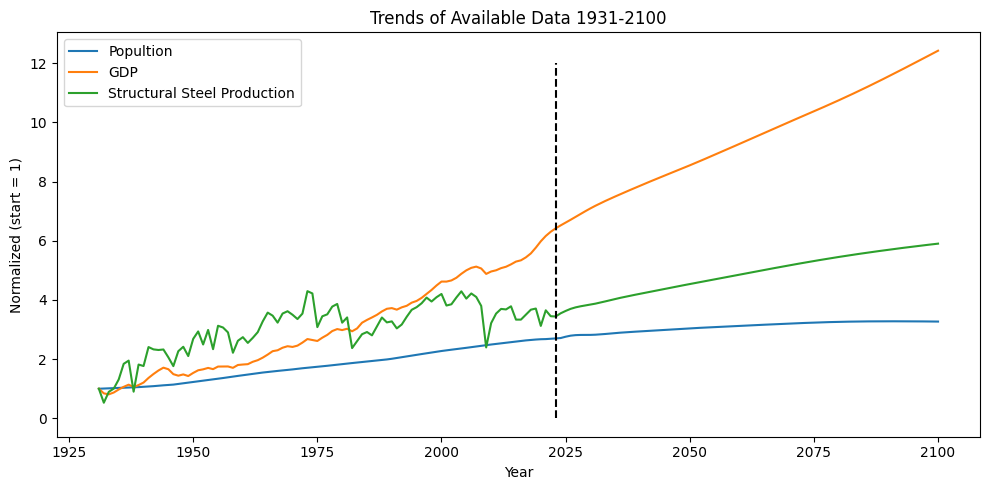

In [ ]:
cols = ['pop_ssp2', 'gdp_ssp2','inflow_ssp2']

years = df_normal.index

labels = {'pop_ssp2': 'Popultion',
           'gdp_ssp2':'GDP',
           'inflow_ssp2':'Structural Steel Production'}

plt.figure(figsize=(10,5))

for col in cols:
    norm = df_normal[col] / df_normal[col].iloc[0]
    plt.plot(years, norm, label=labels[col])

plt.ylabel("Normalized (start = 1)")
plt.xlabel("Year")
plt.plot([2023,2023],[0,12], color = 'k', linestyle = '--')
plt.title("Trends of Available Data 1931-2100")
plt.legend()
plt.show()

In [ ]:
df_normal

,pop_ssp2,gdp_ssp2,inflow_ssp2
1931,1.240396e+08,9931.000000,2396.480000
1932,1.248405e+08,8381.000000,1263.680000
1933,1.255788e+08,8048.000000,2145.890000
1934,1.263738e+08,8667.000000,2406.640000
1935,1.272502e+08,9681.000000,3149.100000
...,...,...,...
2096,4.062801e+08,119845.660276,13953.868896
2097,4.061230e+08,120715.274883,14002.352993
2098,4.059405e+08,121587.065352,14049.959193
2099,4.057335e+08,122460.443214,14096.668125


## Make simple sankey for 2019

In [ ]:
df_recycling

,scrap,Exports,Imports
1998,73000,5950,3370
1999,71000,5560,4020
2000,74000,5810,3630
2001,71000,7530,2810
2002,69000,9000,3320
2003,65000,10900,3690
2004,66600,11800,4790
2005,65600,13000,4000
2006,65300,14100,5000
2007,65000,16700,3780


In [ ]:
df_steel

,total-production,structural-total
1931,23536.93607,2396.48
1932,12411.20919,1263.68
1933,21075.74094,2145.89
1934,23636.72651,2406.64
1935,30928.68612,3149.10
...,...,...
2019,87300.00000,8888.71
2020,73500.00000,7483.62
2021,85900.00000,8746.17
2022,81200.00000,8267.62


In [ ]:
outflow = all_flows['outflow_ssp1'].loc[2019]*.98
waste = all_flows['outflow_ssp1'].loc[2019]*.02
inflow = all_flows['inflow_ssp1'].loc[2019]
scrap = df_recycling['scrap'].loc[2019]+df_recycling['Exports'].loc[2019]-df_recycling['Imports'].loc[2019] - outflow
virgin = 32000
other_use = scrap + virgin - inflow
inflow_reuse = inflow - outflow
other_reuse = scrap + virgin - inflow_reuse

In [ ]:
outflow

np.float64(4335.319203568618)

In [ ]:
import plotly.io as pio
pio.renderers.default = "browser"

In [ ]:
fig = go.Figure(go.Sankey(
    arrangement = "snap",
    node = {
        'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","Construction Scrap", "Waste", "Other Use"],
        # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
        # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
    },
    link = {
        "source" : [0,1,2,3,4,5,5,6,2],
        "target" : [2,2,3,4,5,6,7,1,8],
        "value" : [virgin,scrap,inflow,inflow,inflow,outflow,waste,outflow,other_use]
    }

))

fig.show()

In [ ]:
fig = go.Figure(go.Sankey(
    arrangement = "snap",
    node = {
        'label': ["Virgin", " Scrap", 'Feedstock', "EAF Processing","Fabrication","Built Environment","structural Steel Scrap", "Waste", "Other Use"],
        # 'x' : [0.1, 0.1, 0.3, 0.5, 0.7, 0.8, 0.8, 0.7],
        # 'y' : [0.7, 0.5, 0.5, 0.4, 0.4, 0.3, 0.5, 0.7]
    },
    link = {
        "source" : [0,1,2,3,4,5,5,6,2],
        "target" : [2,2,3,4,5,6,7,4,8],
        "value" : [virgin,scrap,inflow_reuse,inflow_reuse,inflow,outflow,waste,outflow,other_reuse]
    }

))

fig.show()